<a href="https://colab.research.google.com/github/pavlek358/dsb_capstone/blob/main/capstone_clustering_procurement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: clustering public procurement tenders

**Question:** do tenders fall into natural groups, and do some groups look riskier (more delays, more manual reviews)?

**Idea further developed after initial idea of using supervised models:** finding groups without labels (unsupervised), then check the meaning behind the clusters

**Current limitation:** data is syntehtic, the features are limited to the dataset I found in one of the previous projects, idea is to test the approach on a real data consequently


## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

## 2. Load the data

In [ ]:
df = pd.read_csv('synthetic_procurement_data.csv')
print(df.shape)
df.head()

(2500, 13)


,procurement_method,category,agency_type,supplier_region,estimated_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,has_manual_review_flag,budget_change_count,award_delayed
0,direct_award,it_services,municipal,national,79996.15,4,7,0.289,5,21,0,0,1
1,open_tender,office_supplies,municipal,local,13138.56,5,6,0.120,1,29,0,0,1
2,framework_calloff,logistics,education,regional,16533.26,3,5,0.206,5,91,1,0,0
3,selective_tender,logistics,health,local,139399.70,1,2,0.454,2,66,0,1,1
4,open_tender,medical_supplies,municipal,national,26291.71,5,7,0.170,3,94,0,2,0


## 3. Quick EDA

In [ ]:
print('Missing values:', df.isna().sum().sum())
df.describe().round(2)

Missing values: 0


,estimated_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,has_manual_review_flag,budget_change_count,award_delayed
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,33468.79,5.00,7.01,0.20,2.97,63.54,0.19,0.79,0.40
std,32207.00,2.02,2.68,0.12,1.43,32.94,0.39,0.88,0.49
min,5000.00,1.00,0.00,0.00,1.00,7.00,0.00,0.00,0.00
25%,13916.33,4.00,5.00,0.11,2.00,35.00,0.00,0.00,0.00
50%,23541.97,5.00,7.00,0.18,3.00,64.00,0.00,1.00,0.00
75%,41652.40,6.00,9.00,0.27,4.00,92.00,0.00,1.00,1.00
max,380310.04,13.00,18.00,0.75,5.00,119.00,1.00,5.00,1.00


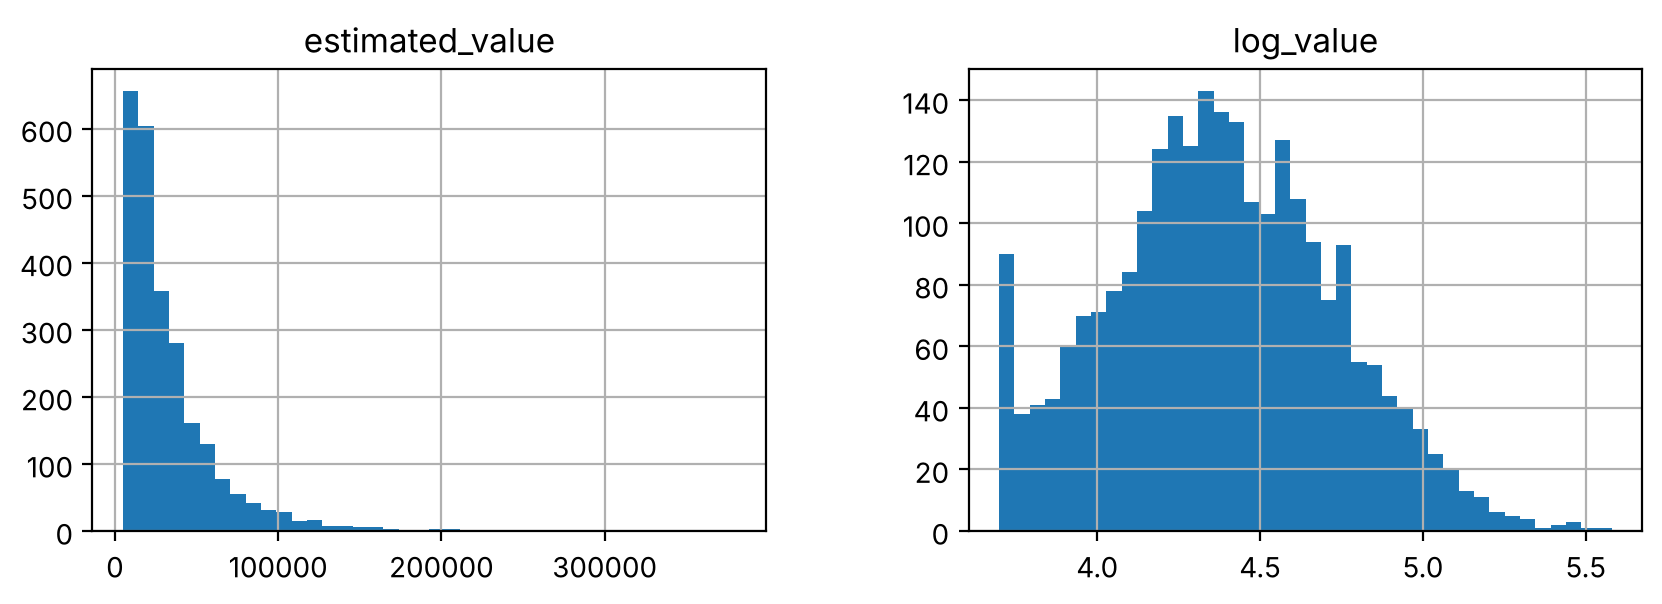

In [ ]:
# Contract value is very skewed, so we use log10 of it
df['log_value'] = np.log10(df['estimated_value'])
df[['estimated_value', 'log_value']].hist(bins=40, figsize=(10, 3));

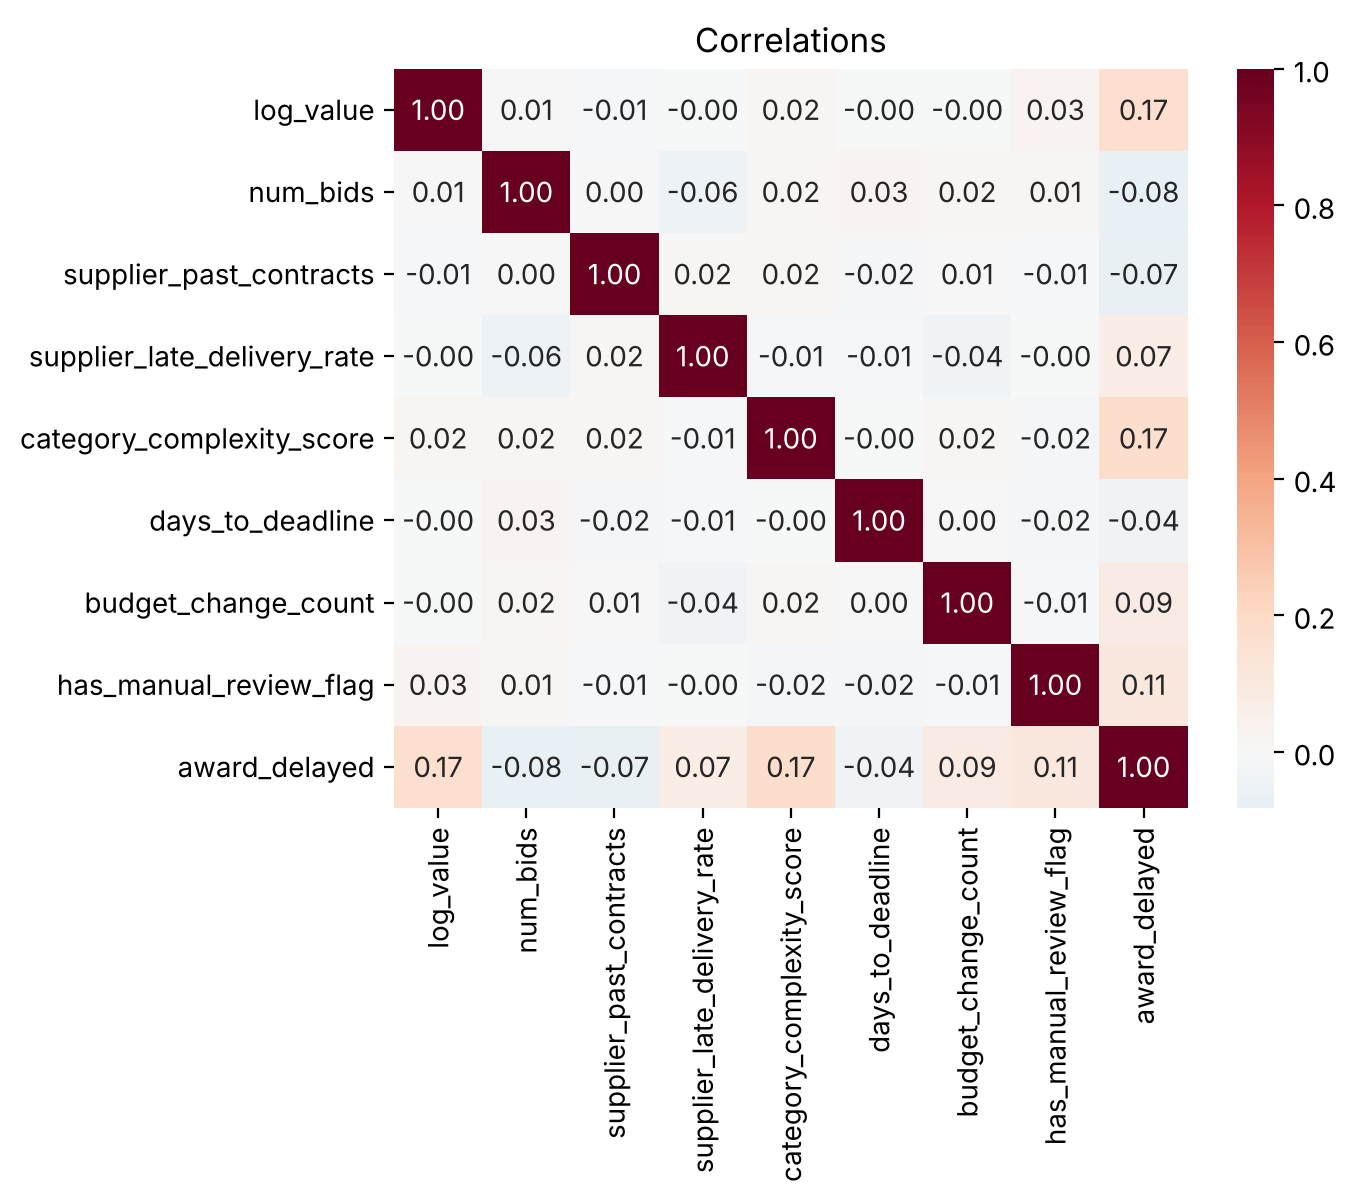

In [ ]:
features = ['log_value', 'num_bids', 'supplier_past_contracts', 'supplier_late_delivery_rate',
            'category_complexity_score', 'days_to_deadline', 'budget_change_count']

sns.heatmap(df[features + ['has_manual_review_flag', 'award_delayed']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlations');

**A:** The features are almost uncorrelated with each other. That is a first hint that strong groups may not exist.

## 4. Choose and scale features
We cluster on the 7 numeric tender features. We **keep out** `has_manual_review_flag`, `award_delayed` and the text columns, and use them later to describe the groups (like Camila's screens).

In [ ]:
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 5. K-Means: choose k (elbow + silhouette)

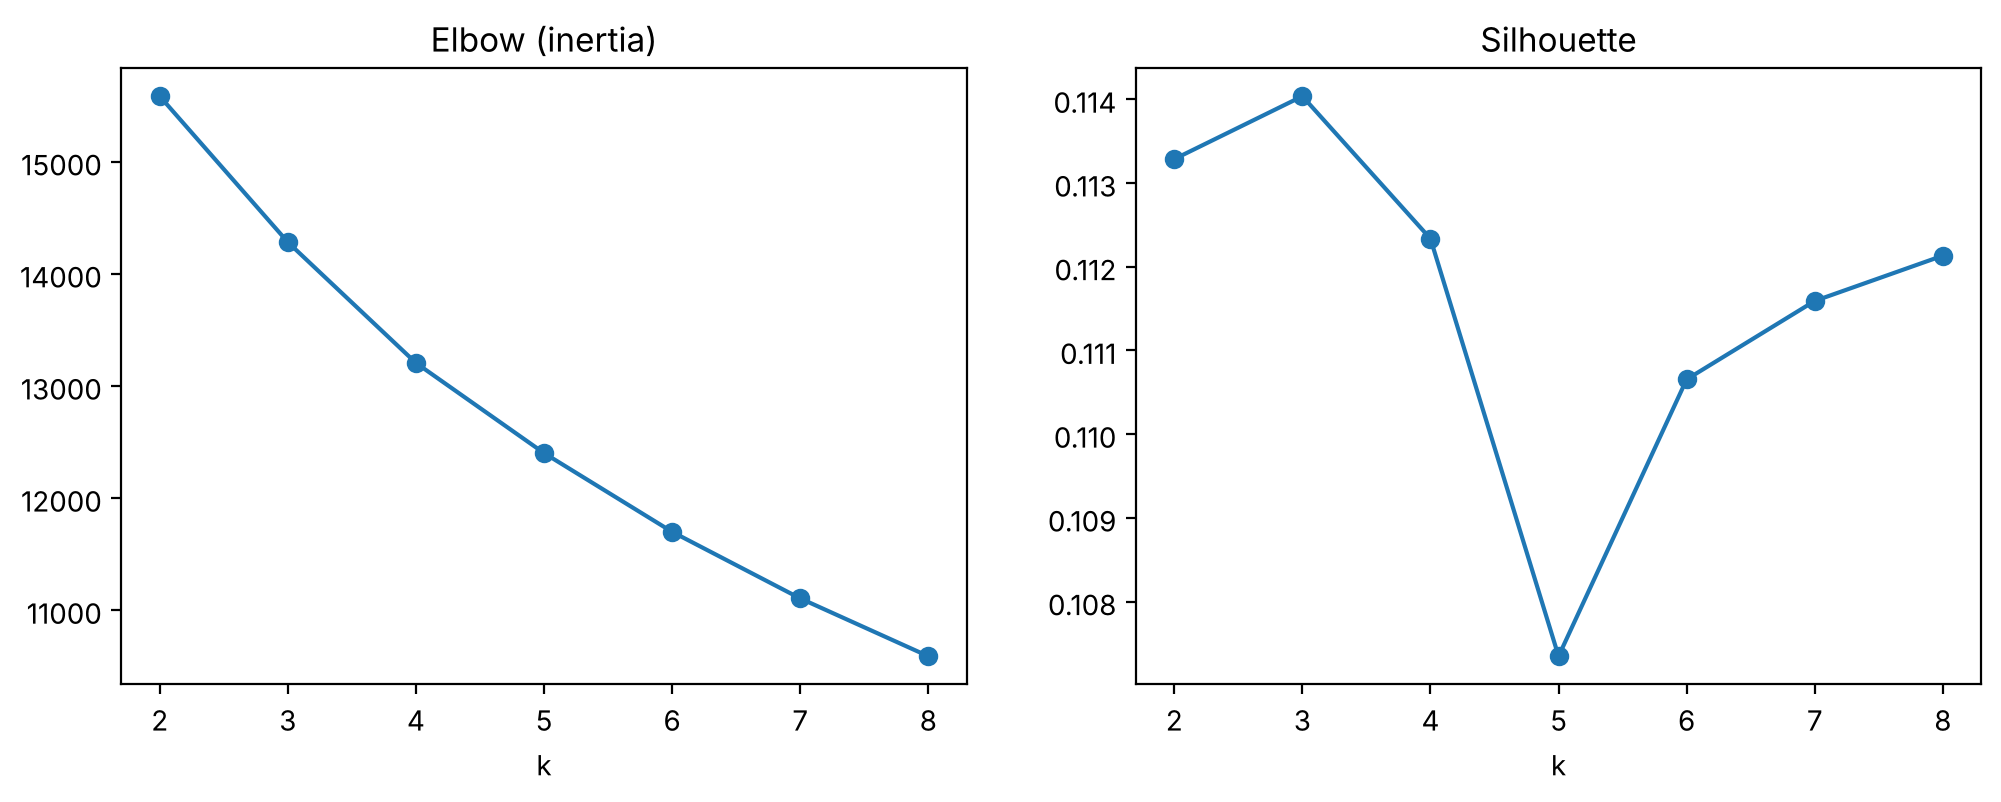

In [ ]:
inertia, sil = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertia, marker='o'); axes[0].set_title('Elbow (inertia)'); axes[0].set_xlabel('k')
axes[1].plot(k_values, sil, marker='o'); axes[1].set_title('Silhouette'); axes[1].set_xlabel('k');

**A:** No clear elbow, and silhouette is about 0.11 for every k (1 = great, 0 = no structure). I pick **k = 3** because it is easy to explain.

In [ ]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
df['cluster'] = km.labels_
df['cluster'].value_counts().sort_index()

cluster
0    1079
1     960
2     461
Name: count, dtype: int64

## 6. Interpret the clusters (profiles)

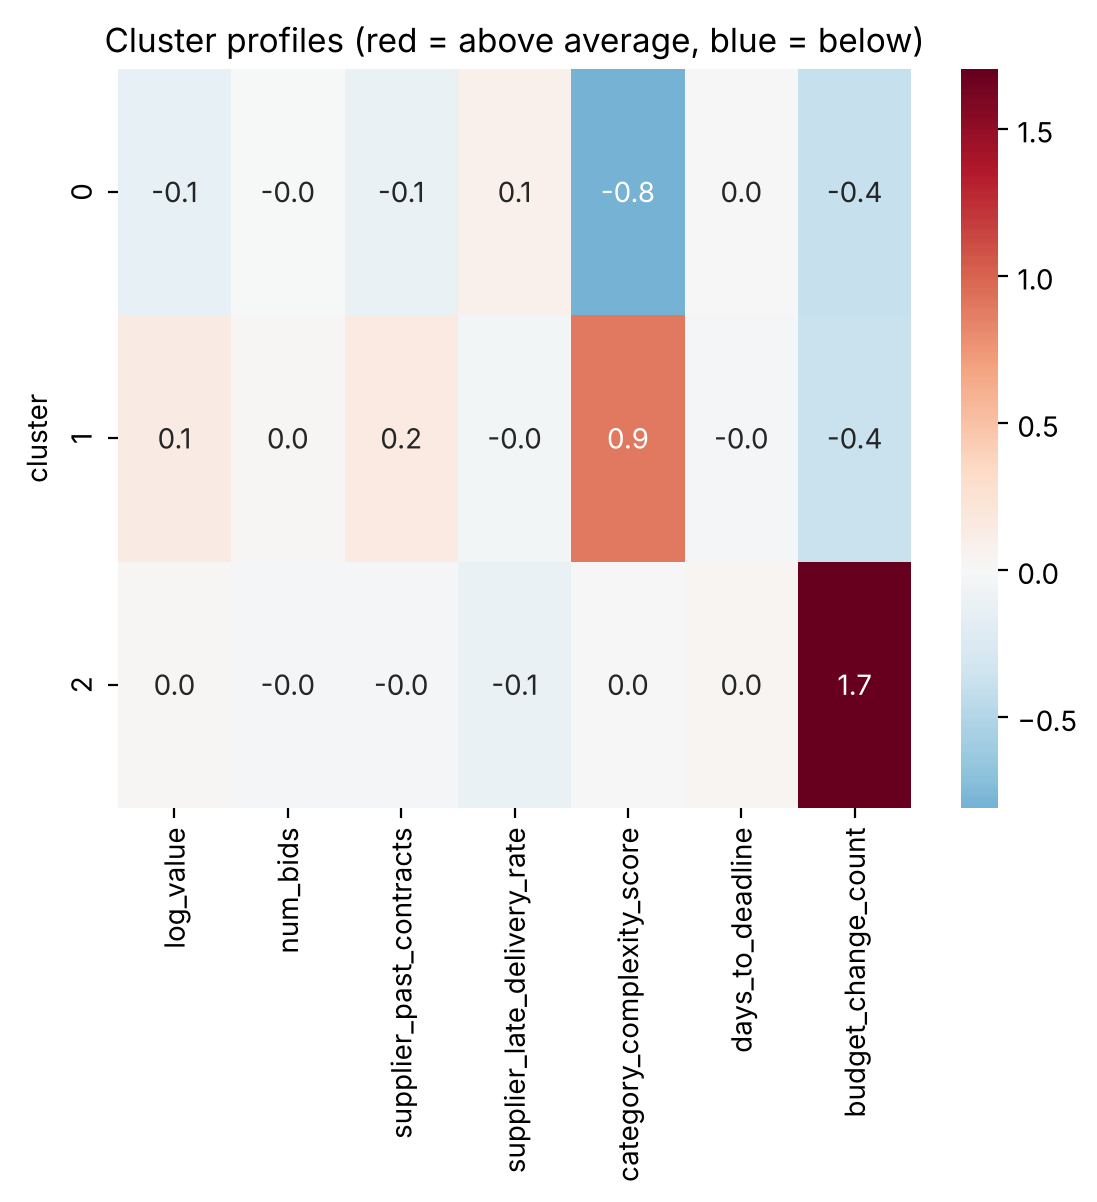

In [ ]:
profile = pd.DataFrame(km.cluster_centers_, columns=features)
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdBu_r', center=0)
plt.ylabel('cluster'); plt.title('Cluster profiles (red = above average, blue = below)');

In [ ]:
# Same thing in original units
df.groupby('cluster')[features].mean().round(2)

,log_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,budget_change_count
cluster,,,,,,,
0,4.34,5.00,6.68,0.21,1.82,64.04,0.45
1,4.43,5.05,7.42,0.19,4.26,62.40,0.46
2,4.39,4.94,6.90,0.18,2.99,64.74,2.29


**A:**
- **Cluster 0:** simple tenders (low complexity), few budget changes.
- **Cluster 1:** complex tenders, few budget changes.
- **Cluster 2:** tenders with **many budget changes**.

Number of bids, supplier history and deadlines are almost the same in all three groups.

## 7. Screens: do some groups look riskier?

In [ ]:
screens = df.groupby('cluster').agg(
    tenders=('cluster', 'size'),
    delayed_rate=('award_delayed', 'mean'),
    manual_review_rate=('has_manual_review_flag', 'mean'),
    avg_bids=('num_bids', 'mean'),
    single_bid_rate=('num_bids', lambda s: (s == 1).mean()),
).round(2)
screens

,tenders,delayed_rate,manual_review_rate,avg_bids,single_bid_rate
cluster,,,,,
0,1079,0.31,0.19,5.00,0.01
1,960,0.47,0.18,5.05,0.03
2,461,0.48,0.20,4.94,0.02


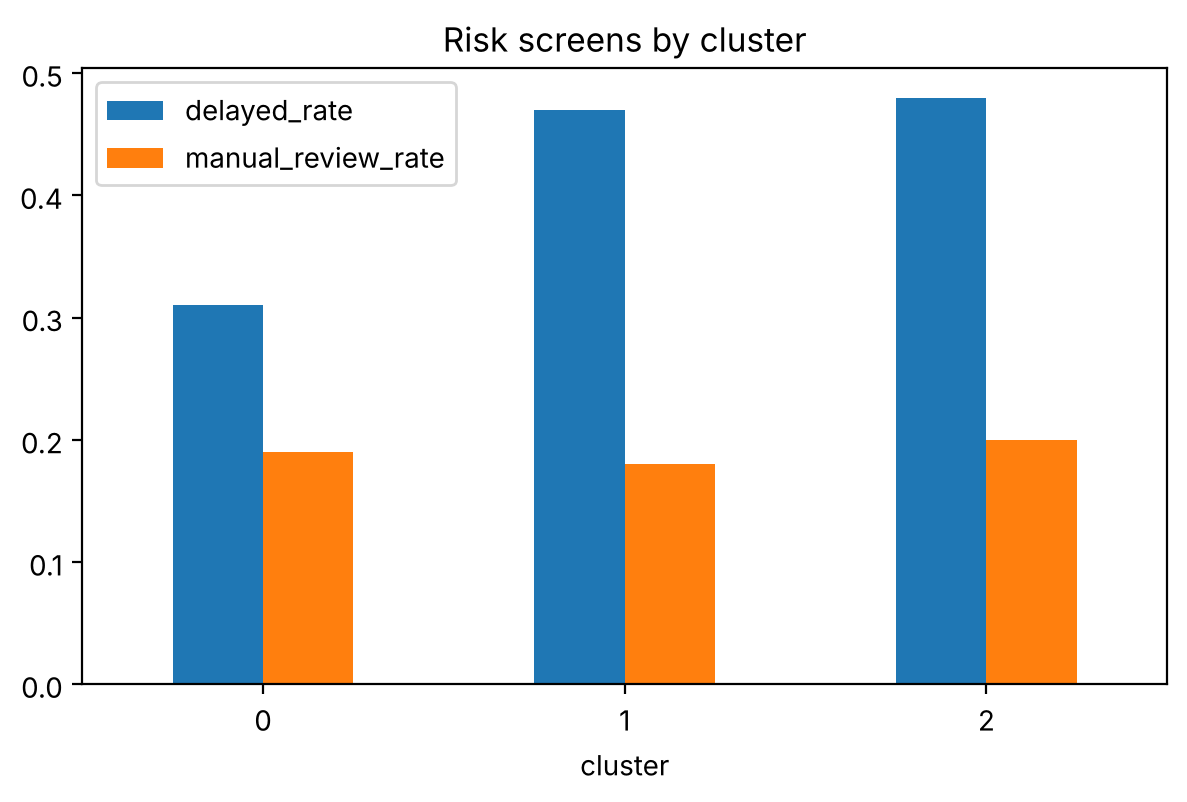

In [ ]:
screens[['delayed_rate', 'manual_review_rate']].plot.bar(figsize=(7, 4), rot=0)
plt.title('Risk screens by cluster');

In [ ]:
# Procurement method mix in each cluster
pd.crosstab(df['cluster'], df['procurement_method'], normalize='index').round(2)

procurement_method,direct_award,framework_calloff,open_tender,selective_tender
cluster,,,,
0,0.14,0.15,0.49,0.22
1,0.15,0.16,0.48,0.21
2,0.18,0.14,0.52,0.17


**A:** Clusters 1 and 2 (complex or many budget changes) are delayed more often (about 47–48%) than cluster 0 (about 31%). Manual review and procurement method look the same everywhere.
Like in Camila's project, this is a **flag for further checking**, not proof of anything.

## 8. Agglomerative clustering (and dendrogram)

In [ ]:
agg = AgglomerativeClustering(n_clusters=3).fit(X_scaled)   # ward linkage
print('Silhouette:', round(silhouette_score(X_scaled, agg.labels_), 3))
pd.crosstab(df['cluster'], agg.labels_, rownames=['k-means'], colnames=['agglomerative'])

Silhouette: 0.06


agglomerative,0,1,2
k-means,,,
0,787,125,167
1,347,540,73
2,375,71,15


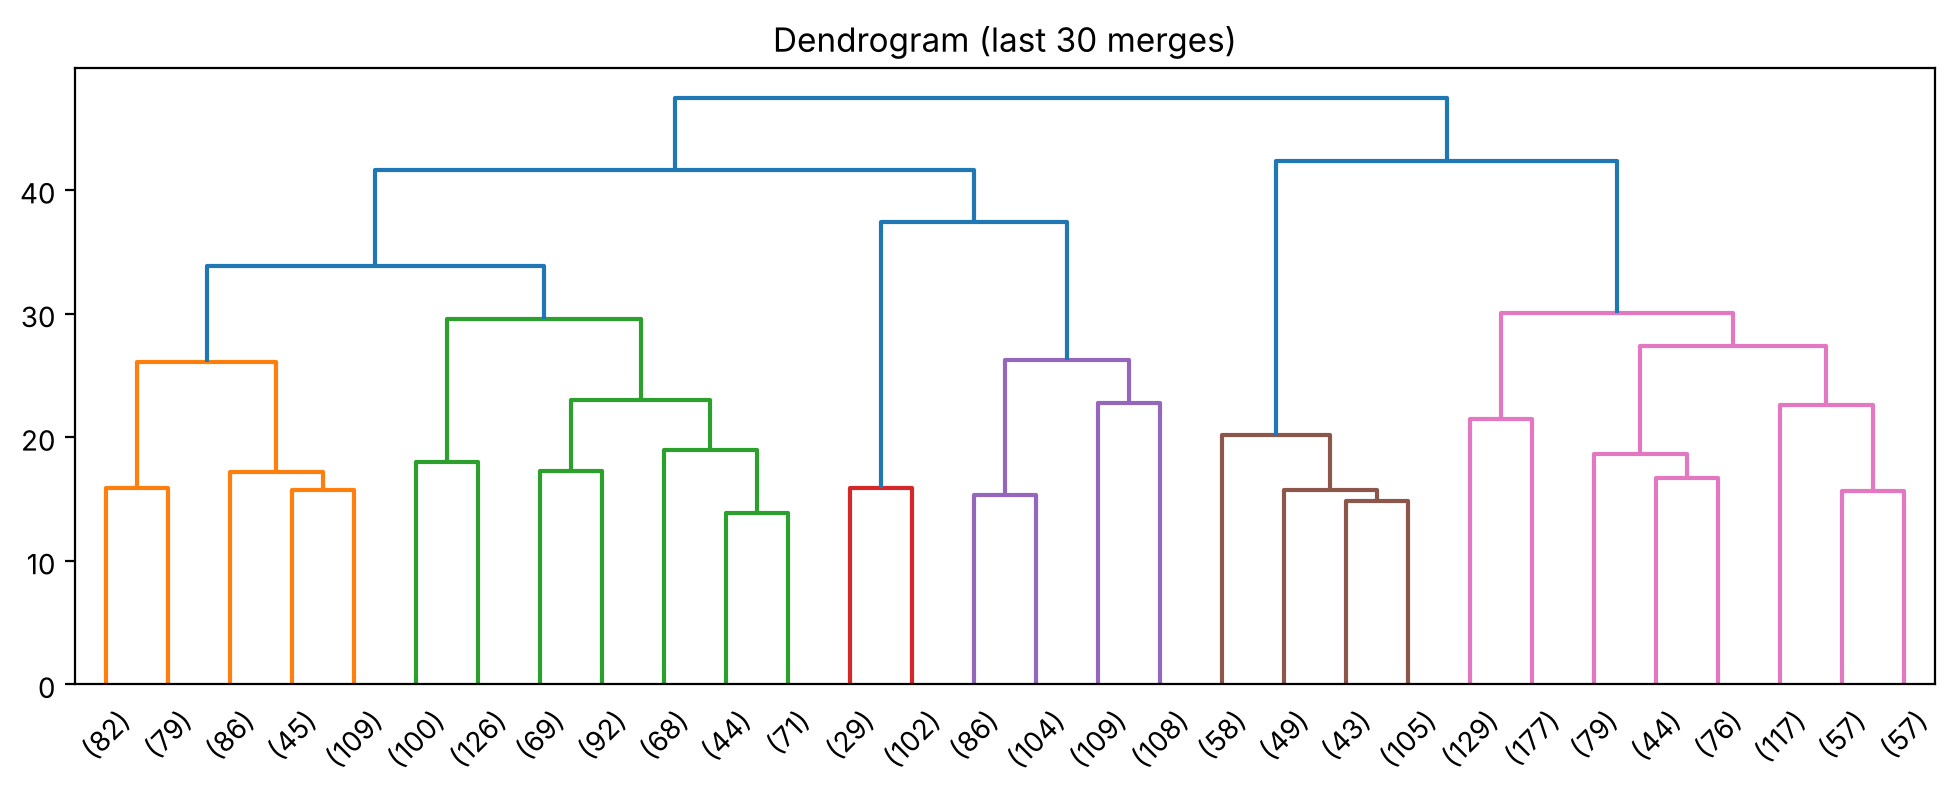

In [ ]:
tree = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 4))
dendrogram(tree, truncate_mode='lastp', p=30)
plt.title('Dendrogram (last 30 merges)');

**A:** Agglomerative gives a lower silhouette (about 0.06) and only partly agrees with K-Means. No long gaps in the dendrogram, so no obvious place to cut.

## 9. DBSCAN (k-distance plot to pick eps)

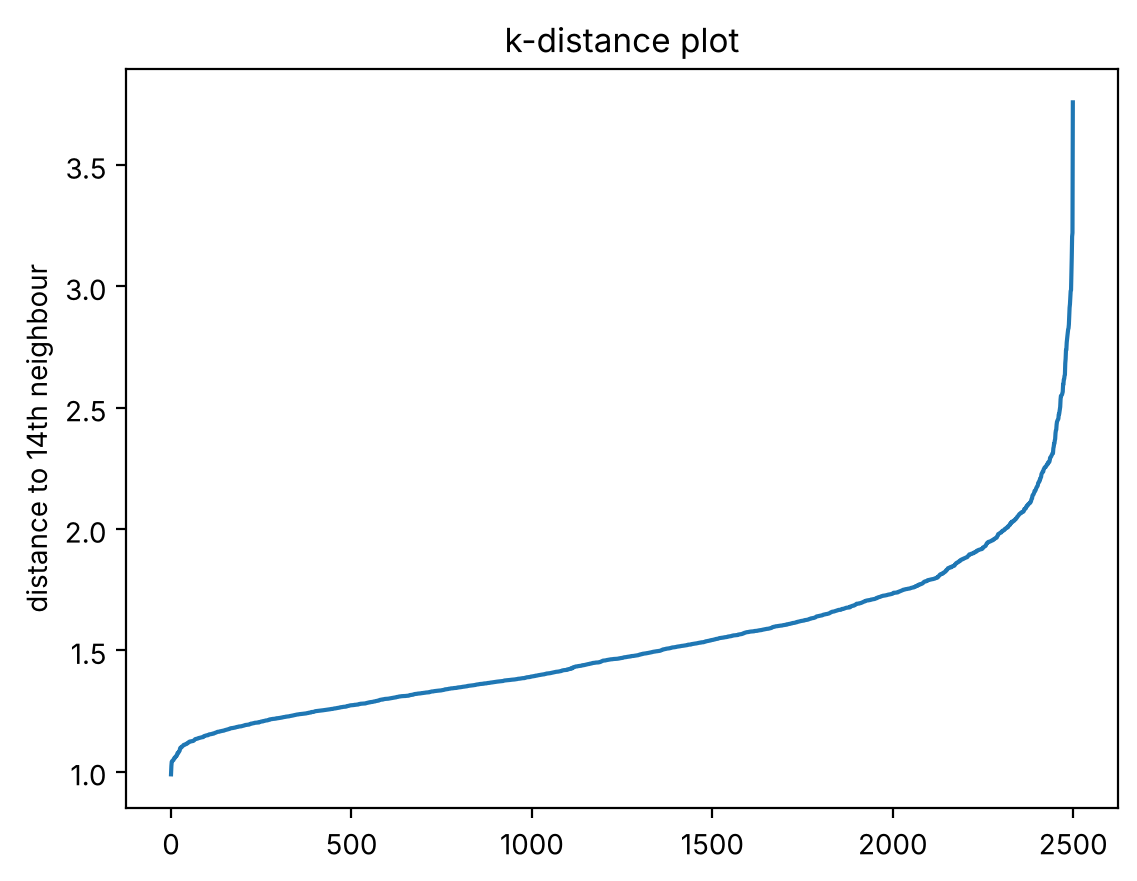

In [ ]:
min_samples = 14   # rule of thumb: 2 x number of features
dist = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
plt.plot(np.sort(dist)); plt.title('k-distance plot'); plt.ylabel(f'distance to {min_samples}th neighbour');

In [ ]:
for eps in [1.0, 1.3, 1.6, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    print(f'eps={eps}: clusters={len(set(labels) - {-1})}, noise={(labels == -1).mean():.0%}')

eps=1.0: clusters=1, noise=99%
eps=1.3: clusters=1, noise=43%
eps=1.6: clusters=1, noise=9%
eps=2.0: clusters=1, noise=1%


**A:** DBSCAN never finds more than **one** cluster. It only separates a dense core from outlier tenders. So the data is one big cloud, not separate groups.

In [ ]:
# Bonus: which tenders does DBSCAN call outliers?
df['outlier'] = DBSCAN(eps=1.6, min_samples=min_samples).fit_predict(X_scaled) == -1
df.groupby('outlier')[features + ['award_delayed']].mean().round(2)

,log_value,num_bids,supplier_past_contracts,supplier_late_delivery_rate,category_complexity_score,days_to_deadline,budget_change_count,award_delayed
outlier,,,,,,,,
False,4.37,4.93,6.88,0.19,2.97,63.39,0.71,0.39
True,4.46,5.76,8.26,0.30,3.01,65.13,1.65,0.48


**A:** The outliers are unusual tenders: more budget changes, suppliers with higher late-delivery rates, more bids. They are delayed more often, so they are a good **shortlist to check**.

## 10. PCA: picture of the clusters in 2D

Variance kept by 2 components: 30%


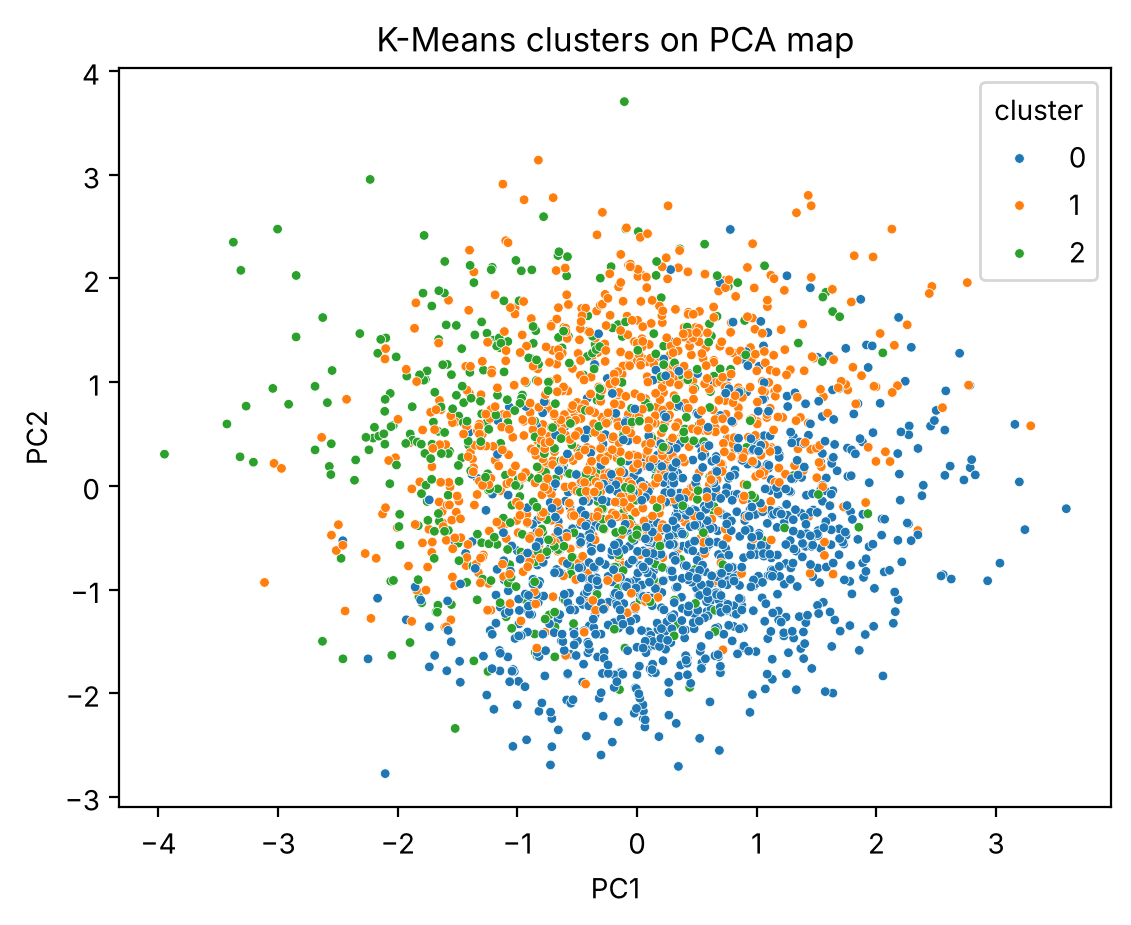

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f'Variance kept by 2 components: {pca.explained_variance_ratio_.sum():.0%}')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['cluster'], palette='tab10', s=12)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('K-Means clusters on PCA map');

**A:** 2 components keep only about 30% of the variation, and the clusters touch each other. K-Means is slicing one cloud, not finding separate groups.

## 11. Compare the algorithms

In [ ]:
pd.DataFrame({
    'algorithm': ['K-Means (k=3)', 'Agglomerative (k=3)', 'DBSCAN'],
    'clusters': [3, 3, 1],
    'silhouette': [round(silhouette_score(X_scaled, km.labels_), 3),
                   round(silhouette_score(X_scaled, agg.labels_), 3), None],
})

,algorithm,clusters,silhouette
0,K-Means (k=3),3,0.114
1,Agglomerative (k=3),3,0.060
2,DBSCAN,1,NaN


## 12. Classification (mentor's suggestion): predict `award_delayed`
Now there **is** a label, so this is supervised. Does adding the cluster number help?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

X_clf = pd.get_dummies(df[features + ['has_manual_review_flag', 'procurement_method', 'category',
                                      'agency_type', 'supplier_region']], drop_first=True)
y = df['award_delayed']
X_train, X_test, y_train, y_test = train_test_split(X_clf, y, test_size=0.25, random_state=42, stratify=y)

print('Baseline (always "not delayed"):', round(1 - y_test.mean(), 2), 'accuracy')

Baseline (always "not delayed"): 0.6 accuracy


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}
for name, model in models.items():
    sc = StandardScaler().fit(X_train)
    model.fit(sc.transform(X_train), y_train)
    auc = roc_auc_score(y_test, model.predict_proba(sc.transform(X_test))[:, 1])
    print(f'{name}: ROC-AUC = {auc:.3f}')

Logistic Regression: ROC-AUC = 0.697


Random Forest: ROC-AUC = 0.666


In [ ]:
# Same logistic regression + cluster dummies
X_clf2 = X_clf.join(pd.get_dummies(df['cluster'], prefix='cluster', drop_first=True))
X_tr2, X_te2 = X_clf2.loc[X_train.index], X_clf2.loc[X_test.index]
sc2 = StandardScaler().fit(X_tr2)
lr2 = LogisticRegression(max_iter=2000).fit(sc2.transform(X_tr2), y_train)
print('Logistic Regression + cluster: ROC-AUC =', round(roc_auc_score(y_test, lr2.predict_proba(sc2.transform(X_te2))[:, 1]), 3))

Logistic Regression + cluster: ROC-AUC = 0.697


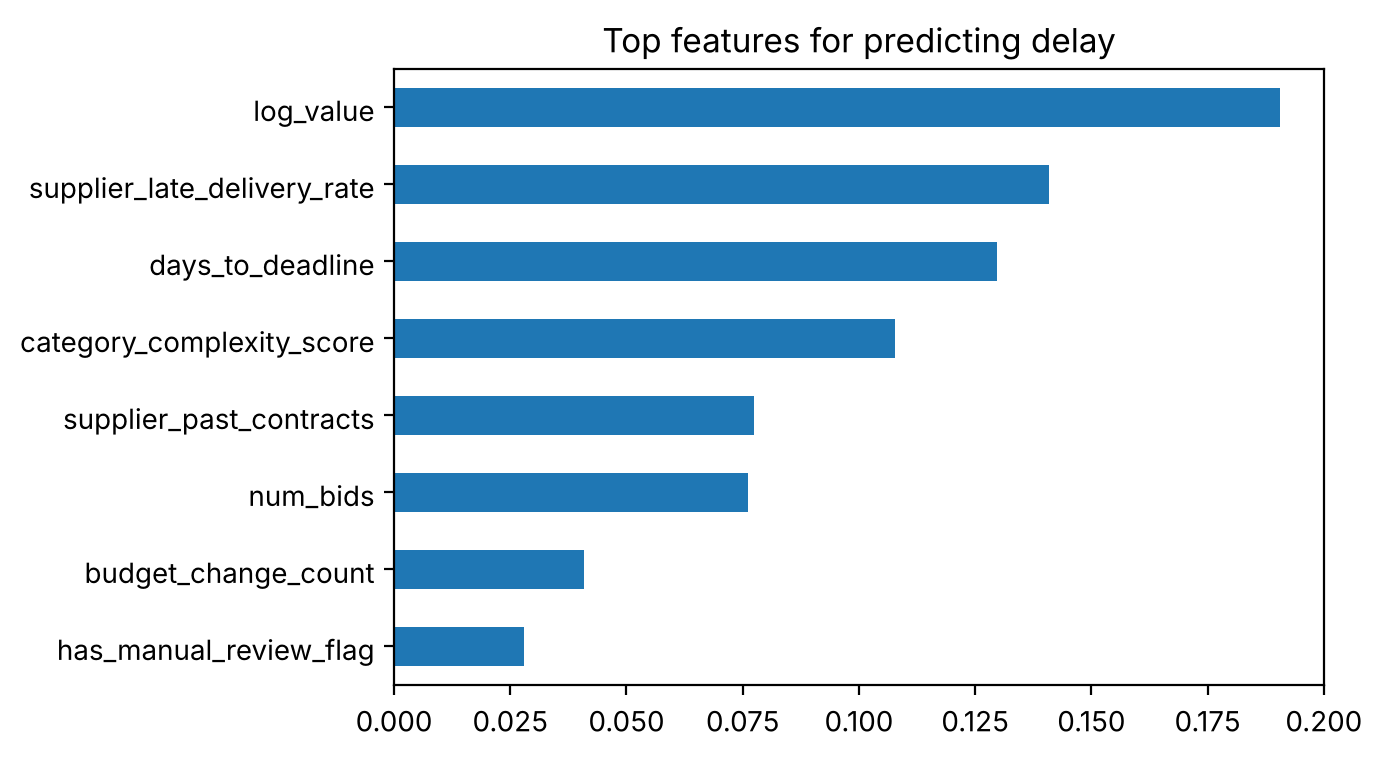

In [ ]:
# Which features matter most? (Random Forest)
rf = models['Random Forest']
pd.Series(rf.feature_importances_, index=X_clf.columns).sort_values().tail(8).plot.barh(figsize=(6, 4))
plt.title('Top features for predicting delay');

**A:** Classification works better than clustering for this question. Adding the cluster number does not help, because the clusters are built from the same features the model already sees.

## 13. Conclusions
- **Weak clusters:** silhouette is about 0.1 and DBSCAN finds one cloud. The tenders don't form strong natural groups.
- **K-Means still gives useful segments:** simple / complex / many budget changes. The last two are delayed more often.
- **DBSCAN outliers** are a practical shortlist of unusual tenders to review.
- **Classification** (predicting delay) is the stronger tool here; contract value, supplier late-delivery rate, deadline and complexity matter most. AUC is about 0.70 (0.5 = guessing), so only moderate.
- **Next step:** I need data with **bidder IDs per tender**, e.g. the Croatian GTI data. Then we can build the co-bidding network in Python